# Assignment 1 — Multiclass Classification: Wine Recognition

## Learning goals

In this assignment, you will classify wines into **three cultivar classes** from 13 chemical-analysis measurements. You will use the Wine Recognition dataset bundled with <b> scikit-learn </b> , so no account, download, or external file is required.

You will complete exploratory data analysis (EDA), engineer features, build leakage-safe preprocessing pipelines, and compare:

- Logistic regression
- Decision tree
- Random forest
- Gradient boosting (GB)

> **Deliverable:** Complete every `TODO`, write concise interpretations under each section, and end with an evidence-based model recommendation.

## Assessment checklist

- [ ] Audit the dataset and target balance
- [ ] Create at least three useful EDA visualisations
- [ ] Engineer at least two meaningful features
- [ ] Split before fitting any learned preprocessing
- [ ] Train logistic regression, decision tree, random forest, and gradient boosting (GB) models
- [ ] Compare accuracy, macro precision, macro recall, and macro F1
- [ ] Tune one model with cross-validation
- [ ] Interpret errors, important features, and limitations

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, ConfusionMatrixDisplay,
                             roc_auc_score, RocCurveDisplay)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)

## 2. Load the Wine Recognition data

The features are laboratory measurements of wines derived from three cultivars. `class_name` is a readable version of the target; do not use it as a predictor.

In [2]:
from sklearn.datasets import load_wine

wine = load_wine(as_frame=True)
df = wine.frame.copy()
df["class_name"] = df["target"].map(dict(enumerate(wine.target_names)))

print("Shape:", df.shape)
df.head()

Shape: (178, 15)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target,class_name
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,class_0


In [3]:
# TODO 1: Audit the dataset.
print(df.dtypes)
print("\nMissing values per column:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nClass counts:")
print(df["class_name"].value_counts().sort_index())
print((df["class_name"].value_counts(normalize=True).sort_index() * 100).round(1))
df.describe().T

alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
target                            int64
class_name                          str
dtype: object

Missing values per column:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue               

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


**Audit observations:**

- The dataset has 178 wines and 13 numeric predictors, with no missing values and no duplicate rows, so no cleaning is needed.
- The classes are a bit unbalanced but not severely: class_1 has 71 wines (39.9%), class_0 has 59 (33.1%) and class_2 has 48 (27.0%). This is why macro averages and a stratified split make sense.
- The scales are very different: proline goes from 278 to 1680 and magnesium from 70 to 162, while hue or nonflavanoid_phenols stay below 2. Standardisation is needed at least for logistic regression.
- Some features have quite large ranges compared with their median (proline, color_intensity, malic_acid), but the values look plausible for lab measurements, so I did not remove anything.

## 3. Exploratory data analysis

EDA should identify class separation, feature distributions, and highly correlated measurements. Use clear plot labels, a readable figure size, and an informative title.

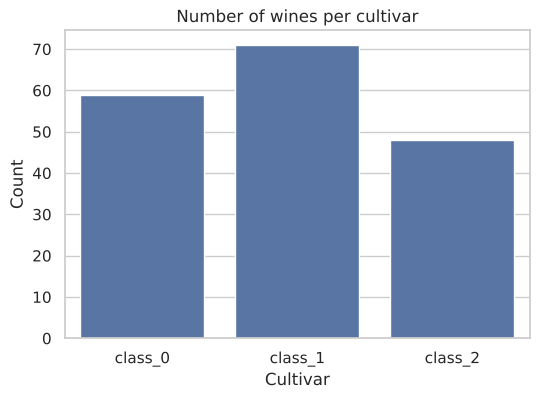

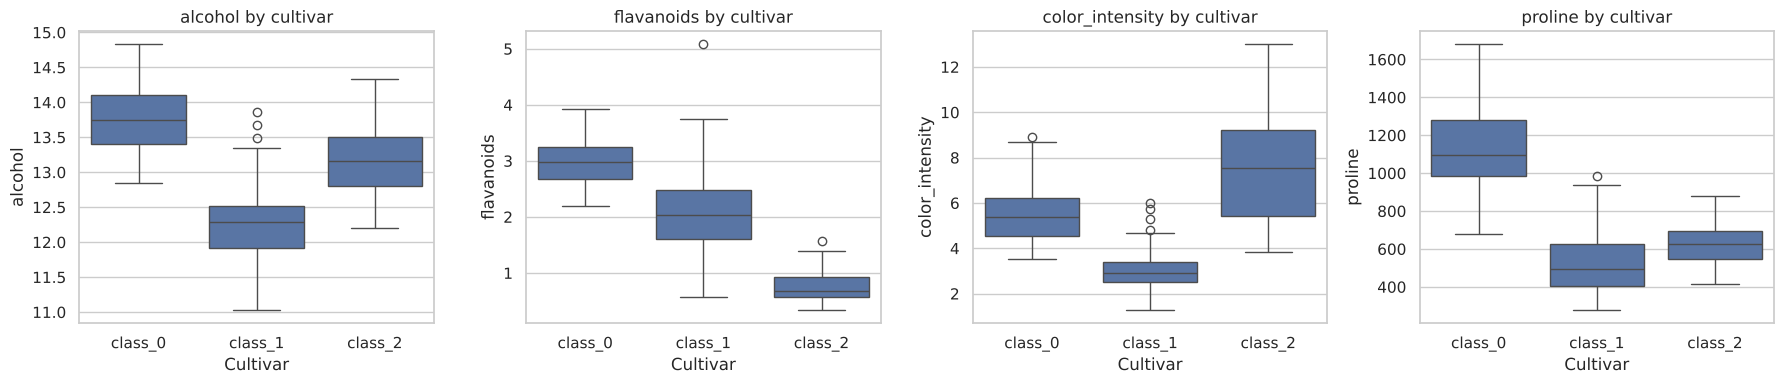

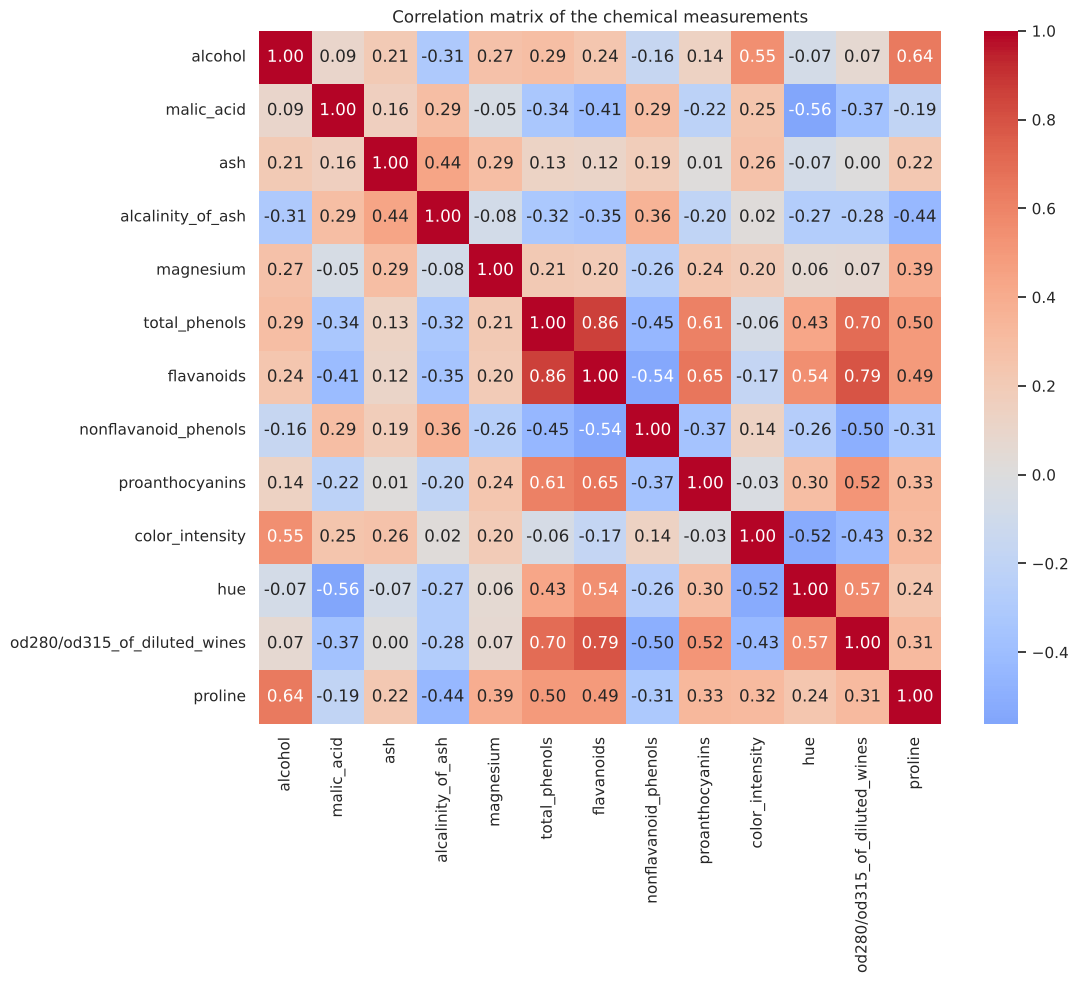

In [4]:
# TODO 2: EDA visualisations

# 1) count plot of class_name
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="class_name", order=sorted(df["class_name"].unique()))
plt.title("Number of wines per cultivar")
plt.xlabel("Cultivar")
plt.ylabel("Count")
plt.show()

# 2) class-wise boxplots for a few features
features_to_plot = ["alcohol", "flavanoids", "color_intensity", "proline"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, features_to_plot):
    sns.boxplot(data=df, x="class_name", y=col, ax=ax)
    ax.set_title(f"{col} by cultivar")
    ax.set_xlabel("Cultivar")
plt.tight_layout()
plt.show()

# 3) correlation heatmap of the numeric predictors
predictors = df.drop(columns=["target", "class_name"])
plt.figure(figsize=(11, 9))
sns.heatmap(predictors.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix of the chemical measurements")
plt.show()

**EDA interpretation:**

The boxplots show that **flavanoids**, **proline** and **color_intensity** separate the cultivars well. Class_0 has high proline (most wines above 1000) and high flavanoids, class_2 has very low flavanoids and the highest color intensity, and class_1 has low color intensity and low proline. Alcohol also helps, mostly to separate class_1 (lower alcohol) from the other two.

The strongest correlation is between **total_phenols and flavanoids (r = 0.86)**, followed by flavanoids and od280/od315 (r = 0.79). This makes sense chemically since flavanoids are a part of the total phenols. It matters because these features carry almost the same information: logistic regression coefficients can become unstable, and tree models may split the importance between them, so importance values for one feature of the pair should be read carefully.

## 4. Feature engineering

Create at least two new predictors from chemical measurements. Do not use `target` or `class_name` when constructing features. Check for missing or infinite values after your transformations.

Ideas (choose or adapt them):

- `phenolics_ratio = total_phenols / nonflavanoid_phenols`
- `alcohol_acidity_ratio = alcohol / malic_acid`
- `color_intensity_per_alcohol = color_intensity / alcohol`
- `proline_per_alcohol = proline / alcohol`

For this small assignment, deterministic calculations that use only each individual row may be created before the split. Later learned transformations must be fit on training data only.

In [5]:
# TODO 3: Feature engineering
df_fe = df.copy()
df_fe["phenolics_ratio"] = df_fe["total_phenols"] / df_fe["nonflavanoid_phenols"]
df_fe["color_intensity_per_alcohol"] = df_fe["color_intensity"] / df_fe["alcohol"]
df_fe["proline_per_alcohol"] = df_fe["proline"] / df_fe["alcohol"]

new_features = ["phenolics_ratio", "color_intensity_per_alcohol", "proline_per_alcohol"]

# check for missing / infinite values
print("Missing:", df_fe[new_features].isna().sum().sum())
print("Infinite:", np.isinf(df_fe[new_features]).sum().sum())

X = df_fe.drop(columns=["target", "class_name"])
y = df_fe["target"]
print("X shape:", X.shape)
df_fe.groupby("class_name")[new_features].mean().round(2)

Missing: 0
Infinite: 0
X shape: (178, 16)


,phenolics_ratio,color_intensity_per_alcohol,proline_per_alcohol
class_name,,,
class_0,10.38,0.40,81.07
class_1,7.36,0.25,42.36
class_2,4.08,0.56,47.99


**Feature rationale:**

- `phenolics_ratio = total_phenols / nonflavanoid_phenols`: compares the total phenolic content with the non-flavanoid part. Class_2 has low phenols but relatively high nonflavanoid phenols, so the ratio drops a lot (mean around 4 against 10 for class_0).
- `color_intensity_per_alcohol = color_intensity / alcohol`: color intensity adjusted for alcohol level. Class_2 has strong colour, class_1 is pale, so this ratio separates them (0.56 vs 0.25).
- `proline_per_alcohol = proline / alcohol`: proline is already the best marker of class_0, and dividing by alcohol keeps that signal (81 for class_0 vs about 42 to 48 for the others).

These are row-wise calculations only, so they can be created before the split without leakage. No missing or infinite values were produced.

## 5. Split and preprocess

Make one stratified train/test split. Standardisation is important for logistic regression because its coefficients depend on feature scale. Tree-based methods do not require scaling, but a common pipeline makes the experiment consistent.

In [6]:
# TODO 4: Split and preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

print("Train:", X_train.shape, " Test:", X_test.shape)
print(y_train.value_counts().sort_index())
print(y_test.value_counts().sort_index())

Train: (133, 16)  Test: (45, 16)
target
0    44
1    53
2    36
Name: count, dtype: int64
target
0    15
1    18
2    12
Name: count, dtype: int64


## 6. Train and compare models

Fit all models only on the training data. In multiclass evaluation, use **macro** averages so every class contributes equally, even if class counts differ.

In [7]:
# TODO 5: Build and fit the pipelines
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

models = {}
for name, clf in classifiers.items():
    pipe = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", clf),
    ])
    pipe.fit(X_train, y_train)
    models[name] = pipe

print(list(models.keys()))

['Logistic Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting']


In [8]:
# TODO 6: Test-set comparison
rows = []
for name, pipe in models.items():
    y_pred = pipe.predict(X_test)
    p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="macro", zero_division=0)
    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, y_pred),
        "macro_precision": p,
        "macro_recall": r,
        "macro_f1": f1,
    })

results = pd.DataFrame(rows).set_index("model").sort_values("macro_f1", ascending=False)
display(results.round(3))

best_name = results.index[0]
print("Strongest model:", best_name)
print(classification_report(y_test, models[best_name].predict(X_test),
                            target_names=wine.target_names))

,accuracy,macro_precision,macro_recall,macro_f1
model,,,,
Random Forest,1.000,1.000,1.000,1.000
Logistic Regression,0.978,0.982,0.972,0.976
Decision Tree,0.956,0.967,0.950,0.956
Gradient Boosting,0.956,0.961,0.954,0.956


Strongest model: Random Forest
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        15
     class_1       1.00      1.00      1.00        18
     class_2       1.00      1.00      1.00        12

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



**Comparison interpretation:**

The **Random Forest** leads with a macro F1 of 1.00 (no error on the 45 test wines). Logistic regression is close behind (macro F1 = 0.976, 1 error), and the Decision Tree and Gradient Boosting both get 0.956 (2 errors each).

Accuracy and macro F1 give almost the same ranking here, because the test classes are fairly balanced and the errors are few. The small differences come from which class is hit: for logistic regression, the single error is a class_2 wine predicted as class_1, so macro recall (0.972) is a bit lower than accuracy (0.978), since class_2 is the smallest class and one mistake costs it more. With only 45 test samples, one wine changes accuracy by about 2 points, so the gap between the models is small.

## 7. Error analysis and interpretation

Confusion matrices reveal *which* cultivars are confused. Feature importance from a tree model indicates which predictors the model used most; it is not causal evidence.

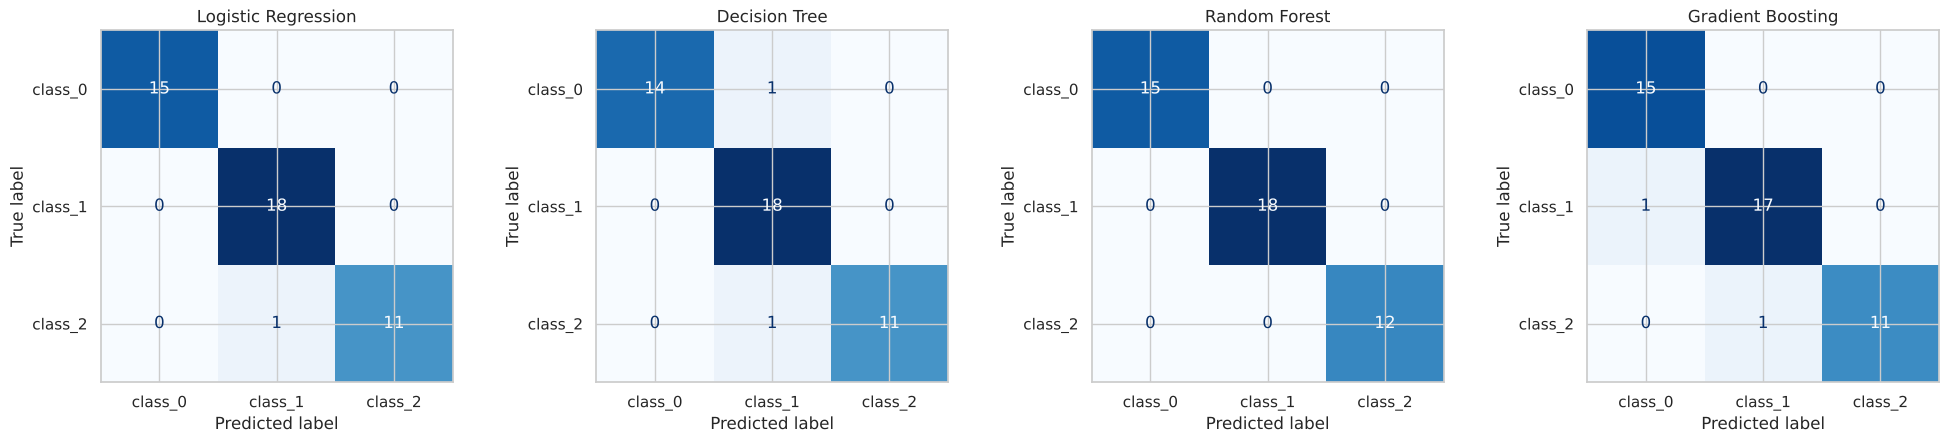

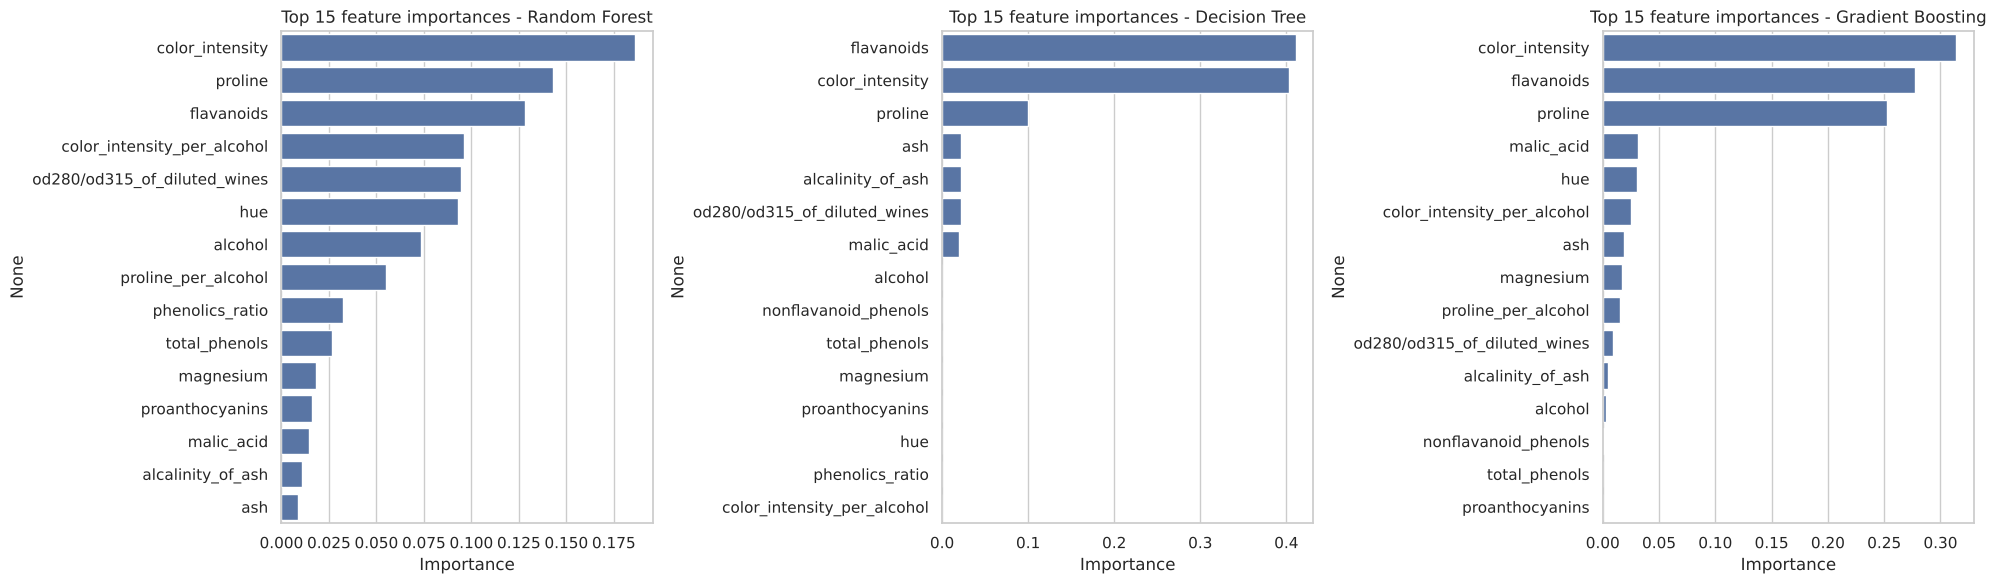

In [9]:
# TODO 7: Confusion matrices and feature importances
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (name, pipe) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test,
                                          display_labels=wine.target_names,
                                          ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, name in zip(axes, ["Random Forest", "Decision Tree", "Gradient Boosting"]):
    importances = pd.Series(models[name].named_steps["model"].feature_importances_, index=X.columns)
    top15 = importances.sort_values(ascending=False).head(15)
    sns.barplot(x=top15.values, y=top15.index, ax=ax)
    ax.set_title(f"Top 15 feature importances - {name}")
    ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

## 8. Hyperparameter tuning

TODO 8: Choose one of the following models: Decision Tree, Random Forest,
or Gradient Boosting, and tune it using GridSearchCV with stratified 5-fold
cross-validation.

Optimise `f1_macro` and do not use the test set while choosing parameters.

Select a suitable hyperparameter grid according to your choice.

Report the best parameters and the best cross-validation score.

In [10]:
# TODO 8: Tune the Random Forest with GridSearchCV
from sklearn.model_selection import GridSearchCV

rf_pipe = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestClassifier(random_state=RANDOM_STATE)),
])

param_grid = {
    "model__n_estimators": [100, 300],
    "model__max_depth": [None, 3, 5],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", 0.5],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(rf_pipe, param_grid, cv=cv, scoring="f1_macro", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best mean CV macro F1:", round(grid.best_score_, 4))

y_pred_tuned = grid.best_estimator_.predict(X_test)
p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred_tuned, average="macro")
print("\nHeld-out test set:")
print("accuracy       :", round(accuracy_score(y_test, y_pred_tuned), 4))
print("macro precision:", round(p, 4))
print("macro recall   :", round(r, 4))
print("macro F1       :", round(f1, 4))

Best parameters: {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 4, 'model__n_estimators': 100}
Best mean CV macro F1: 0.978

Held-out test set:
accuracy       : 1.0
macro precision: 1.0
macro recall   : 1.0
macro F1       : 1.0


## 9. Final reflection

I would recommend the **Random Forest**. On the test set it reached 1.00 accuracy and 1.00 macro F1, and after tuning with stratified 5-fold CV the best configuration (100 trees, min_samples_leaf=4, max_features='sqrt') got a mean CV macro F1 of 0.978, which is a more realistic estimate than the perfect test score. Logistic regression is a good simpler alternative (0.976 macro F1).

The most informative features were **color_intensity**, **proline** and **flavanoids**, which are at the top for all three tree models. The engineered feature color_intensity_per_alcohol also appeared in the top 5 of the Random Forest.

The few errors made by the other models mostly involve **class_1**: class_2 wines predicted as class_1 (logistic regression, Decision Tree, Gradient Boosting) and one class_0 predicted as class_1. Class_1 sits between the two other cultivars on several measurements, which explains these confusions.

Limitations: the dataset is very small (178 wines, 45 in the test set), so a single misclassified wine changes the scores by about 2 points and a perfect score should not be over-interpreted. Several predictors are strongly correlated (flavanoids, total_phenols, od280), which makes feature importances less reliable. The wines all come from one region, so the model may not work on wines from other origins.

As a next step, I would use repeated stratified cross-validation on the whole dataset to get a mean and a confidence interval for the scores instead of relying on a single split.